**This notebook is created for presenting** **"otto-conversion-analysis" repository on GitHub. For further** **information:** [Repository Link](https://github.com/Ahmet-Can-Urhan/otto-conversion-analysis)

# OTTO Conversion Analysis

### E-Commerce Customer Behavior and Purchase Conversion Analysis

---

## Table of Contents

# 1. Business Understanding

## 1.1 Business Problem

E-commerce platforms generate large amounts of behavioral data during customer sessions. Understanding how users interact with products and how these interactions relate to purchases can help identify opportunities to improve purchase conversion.

This project analyzes session-level user behavior in the OTTO e-commerce dataset to identify behavioral patterns associated with successful purchases.

## 1.2 Project Objective

The main objective is to analyze e-commerce session behavior, identify characteristics associated with purchase conversion, and use statistical analysis to derive actionable business insights.

The analysis focuses on user interactions such as product clicks, cart additions, purchases, product exploration, and session duration.

## 1.3 Research Questions

The analysis is guided by the following research questions:

- **RQ1 — Behavioral Analysis:** How do users interact with products during e-commerce sessions?
- **RQ2 — Conversion Analysis:** What behavioral characteristics distinguish sessions that result in purchases from those that do not?
- **RQ3 — Purchase Funnel:** How does user activity progress from product clicks to cart additions and ultimately to purchases?
- **RQ4 — Association Analysis:** How strongly are different session-level behavioral characteristics associated with purchase conversion?
- **RQ5 — Business Strategy:** What actionable strategies can an e-commerce platform implement to improve purchase conversion based on the observed behavioral patterns?

# 2. Data Understanding

## 2.1 Dataset Description
The dataset is stored in JSON Lines (.jsonl) format, where each line represents one session and contains the session identifier together with its sequence of events.

The analysis is performed at the session level, allowing individual event sequences to be transformed into behavioral features that can later be used to investigate purchase conversion.


## 2.2 Data Structure

Each session contains a session identifier and a list of events. Each event contains:

- `aid` — the anonymized product identifier.
- `ts` — the event timestamp in milliseconds.
- `type` — the type of interaction (`clicks`, `carts`, or `orders`).

A simplified representation of the data is:

```text
Session
├── session
└── events
    ├── aid
    ├── ts
    └── type
```

The event-level structure will later be transformed into session-level behavioral features for analysis.


## 2.3 Data Acquisition

The original OTTO dataset is available through the Kaggle OTTO Recommender Systems competition.

The raw dataset is not stored in the GitHub repository because of its large file size. Instead, the data is obtained separately and processed locally.

For this project, a 200,000-session sample was prepared as:

```text
data/raw/train_200k.jsonl
```

This approach keeps the GitHub repository lightweight while allowing the analysis notebook to work with the required dataset.

In [1]:
from pathlib import Path
import json

DATA_PATH = Path("../data/raw/train_200k.jsonl")

print(f"Dataset exists: {DATA_PATH.exists()}")
print(f"Dataset size: {DATA_PATH.stat().st_size / (1024**2):.2f} MB")

Dataset exists: True
Dataset size: 499.29 MB


In [2]:
with open(DATA_PATH, "r") as f:
    first_session = json.loads(f.readline())

first_session

{'session': 0,
 'events': [{'aid': 1517085, 'ts': 1659304800025, 'type': 'clicks'},
  {'aid': 1563459, 'ts': 1659304904511, 'type': 'clicks'},
  {'aid': 1309446, 'ts': 1659367439426, 'type': 'clicks'},
  {'aid': 16246, 'ts': 1659367719997, 'type': 'clicks'},
  {'aid': 1781822, 'ts': 1659367871344, 'type': 'clicks'},
  {'aid': 1152674, 'ts': 1659367885796, 'type': 'clicks'},
  {'aid': 1649869, 'ts': 1659369893840, 'type': 'carts'},
  {'aid': 461689, 'ts': 1659369898050, 'type': 'carts'},
  {'aid': 305831, 'ts': 1659370027105, 'type': 'orders'},
  {'aid': 461689, 'ts': 1659370027105, 'type': 'orders'},
  {'aid': 362233, 'ts': 1659370064916, 'type': 'clicks'},
  {'aid': 1649869, 'ts': 1659370067686, 'type': 'clicks'},
  {'aid': 1649869, 'ts': 1659371003682, 'type': 'clicks'},
  {'aid': 984597, 'ts': 1659371033243, 'type': 'clicks'},
  {'aid': 1649869, 'ts': 1659371042297, 'type': 'clicks'},
  {'aid': 803544, 'ts': 1659371044075, 'type': 'clicks'},
  {'aid': 1110941, 'ts': 1659371104329, '

## 2.4 Initial Data Exploration

Before preparing the data for analysis, the dataset is examined to understand its size, event distribution, and session characteristics.

The initial exploration focuses on:

- the number of sessions,
- the total number of events,
- the distribution of event types,
- the number of events per session,
- and the basic structure of the observed behavioral data.

In [3]:
session_count = 0
total_events = 0

with open(DATA_PATH, "r") as f:
    for line in f:
        session = json.loads(line)

        session_count += 1
        total_events += len(session["events"])

print(f"Number of sessions: {session_count:,}")
print(f"Total number of events: {total_events:,}")

Number of sessions: 200,000
Total number of events: 10,285,561


In [4]:
event_counts = {
    "clicks": 0,
    "carts": 0,
    "orders": 0
}

with open(DATA_PATH, "r") as f:
    for line in f:
        session = json.loads(line)

        for event in session["events"]:
            event_counts[event["type"]] += 1

event_counts

{'clicks': 9320528, 'carts': 751785, 'orders': 213248}

In [5]:
import pandas as pd

event_counts_df = pd.DataFrame(
    event_counts.items(),
    columns=["Event Type", "Count"]
)

event_counts_df

,Event Type,Count
0,clicks,9320528
1,carts,751785
2,orders,213248


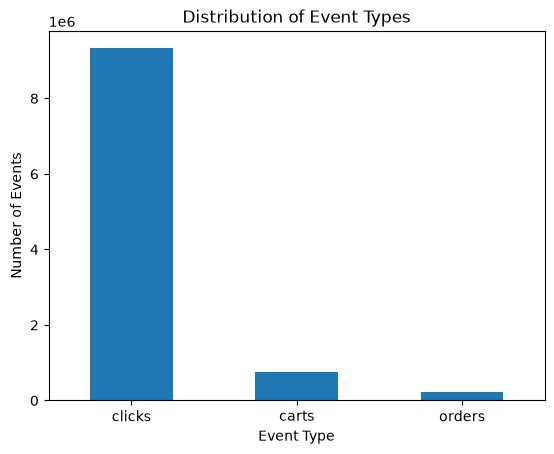

In [6]:
import matplotlib.pyplot as plt

event_counts_df.plot(
    x="Event Type",
    y="Count",
    kind="bar",
    legend=False
)

plt.title("Distribution of Event Types")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.xticks(rotation=0)
plt.show()

In [7]:
events_per_session = []

with open(DATA_PATH, "r") as f:
    for line in f:
        session = json.loads(line)
        events_per_session.append(len(session["events"]))

events_per_session_series = pd.Series(events_per_session)

events_per_session_series.describe()

count    200000.000000
mean         51.427805
std          75.456583
min           2.000000
25%           6.000000
50%          19.000000
75%          62.000000
max         495.000000
dtype: float64

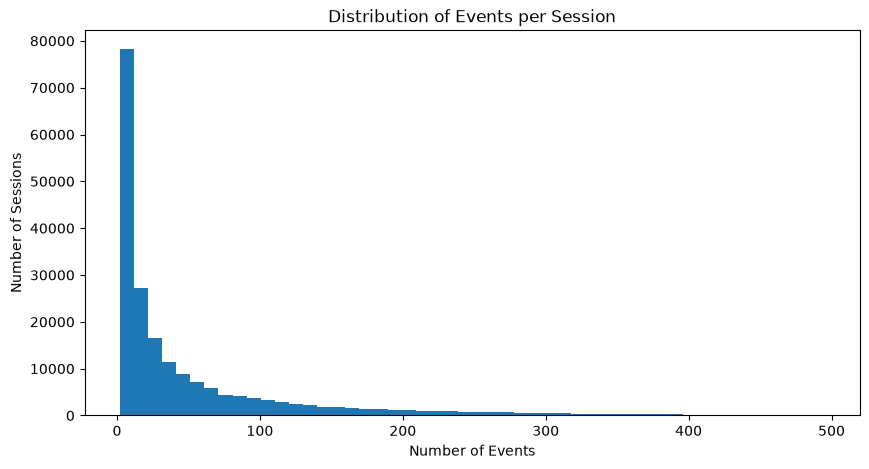

In [8]:
plt.figure(figsize=(10, 5))

plt.hist(events_per_session_series, bins=50)

plt.title("Distribution of Events per Session")
plt.xlabel("Number of Events")
plt.ylabel("Number of Sessions")

plt.show()

## 2.5 Data Quality

Before constructing session-level features, the raw event data is checked for potential quality issues.

The following aspects are examined:

- Missing or malformed session records
- Missing event attributes
- Invalid event types
- Duplicate session identifiers
- Invalid timestamps
- Empty event sequences

These checks help ensure that the data is suitable for the subsequent data preparation and analysis stages.

In [9]:
session_ids = []

with open(DATA_PATH, "r") as f:
    for line in f:
        session = json.loads(line)
        session_ids.append(session["session"])

session_ids_series = pd.Series(session_ids)

print(f"Total session IDs: {len(session_ids_series):,}")
print(f"Unique session IDs: {session_ids_series.nunique():,}")
print(f"Duplicate session IDs: {session_ids_series.duplicated().sum():,}")

Total session IDs: 200,000
Unique session IDs: 200,000
Duplicate session IDs: 0


In [10]:
invalid_timestamps = 0
total_events_checked = 0

with open(DATA_PATH, "r") as f:
    for line in f:
        session = json.loads(line)

        for event in session["events"]:
            total_events_checked += 1

            ts = event.get("ts")

            if not isinstance(ts, (int, float)) or ts <= 0:
                invalid_timestamps += 1

print(f"Events checked: {total_events_checked:,}")
print(f"Invalid timestamps: {invalid_timestamps:,}")

Events checked: 10,285,561
Invalid timestamps: 0


In [11]:
required_event_fields = {"aid", "ts", "type"}

missing_field_counts = {
    "aid": 0,
    "ts": 0,
    "type": 0
}

invalid_event_types = set()
empty_sessions = 0

with open(DATA_PATH, "r") as f:
    for line in f:
        session = json.loads(line)

        if not session.get("events"):
            empty_sessions += 1

        for event in session.get("events", []):
            for field in required_event_fields:
                if field not in event:
                    missing_field_counts[field] += 1

            if event.get("type") not in {"clicks", "carts", "orders"}:
                invalid_event_types.add(event.get("type"))

print("Missing fields:")
print(missing_field_counts)

print("\nInvalid event types:")
print(invalid_event_types)

print("\nEmpty sessions:", empty_sessions)

Missing fields:
{'aid': 0, 'ts': 0, 'type': 0}

Invalid event types:
set()

Empty sessions: 0


### Data Quality Summary

The data quality checks identified no structural issues in the analyzed sample. All 200,000 sessions have unique session identifiers, and no duplicate session IDs were detected.

Across the 10,285,561 observed events, there were no missing `aid`, `ts`, or `type` fields. All events belonged to one of the expected event types: `clicks`, `carts`, or `orders`. No empty sessions or invalid timestamps were detected.

Therefore, no structural cleaning is required at this stage, and the dataset can proceed to the **Data Preparation** phase.

# 3. Data Preparation

## 3.1 Data Cleaning

The data quality assessment identified no missing event attributes, invalid event types, duplicate session identifiers, empty sessions, or invalid timestamps in the analyzed sample.

Therefore, no records are removed during the initial cleaning stage. The raw event data is retained, and the main preparation task is to transform the event-level structure into session-level analytical features.

## 3.2 Event Processing

The raw dataset stores user interactions as sequences of events within each session. To enable session-level analysis, each event is classified according to its interaction type.

The three event types are:

- `clicks` — product interactions
- `carts` — cart additions
- `orders` — purchases

For each session, these events will be aggregated into numerical behavioral features.

## 3.3 Session-Level Aggregation

The original dataset is event-based, while the research questions require comparisons between e-commerce sessions.

Therefore, the event sequences are aggregated at the session level. For each session, behavioral characteristics such as the number of clicks, cart additions, purchases, unique products, and session duration are calculated.

This produces a structured analytical dataset in which each row represents one session.

In [14]:
session_data = []

with open(DATA_PATH, "r") as f:
    for line in f:
        session = json.loads(line)

        session_id = session["session"]
        events = session["events"]

        # Separate events by type
        click_count = 0
        cart_count = 0
        order_count = 0

        # Products interacted with during the session
        products = set()

        # Timestamps
        timestamps = []

        for event in events:
            event_type = event["type"]
            aid = event["aid"]
            ts = event["ts"]

            products.add(aid)
            timestamps.append(ts)

            if event_type == "clicks":
                click_count += 1
            elif event_type == "carts":
                cart_count += 1
            elif event_type == "orders":
                order_count += 1

        session_data.append({
            "session_id": session_id,
            "click_count": click_count,
            "cart_count": cart_count,
            "order_count": order_count,
            "unique_products": len(products),
            "session_duration_ms": max(timestamps) - min(timestamps)
        })

In [15]:
session_df = pd.DataFrame(session_data)

session_df.head()

,session_id,click_count,cart_count,order_count,unique_products,session_duration_ms
0,0,255,17,4,183,2380183682
1,1,24,8,0,22,2410054967
2,2,32,1,0,29,2409415621
3,3,200,21,5,140,1804866676
4,4,15,3,1,12,2281881184


In [16]:
session_df.shape

(200000, 6)

In [17]:
session_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 6 columns):
 #   Column               Non-Null Count   Dtype
---  ------               --------------   -----
 0   session_id           200000 non-null  int64
 1   click_count          200000 non-null  int64
 2   cart_count           200000 non-null  int64
 3   order_count          200000 non-null  int64
 4   unique_products      200000 non-null  int64
 5   session_duration_ms  200000 non-null  int64
dtypes: int64(6)
memory usage: 9.2 MB


## 3.4 Feature Construction

To analyze purchase conversion, a binary `converted` feature is created at the session level.

A session is considered **converted** if it contains at least one `orders` event. Sessions without an `orders` event are considered non-converted.

The resulting feature is defined as:

- `converted = 1` if `order_count > 0`
- `converted = 0` if `order_count = 0`

Additional derived features will be created where necessary for the subsequent behavioral and statistical analyses.

In [18]:
session_df["converted"] = (
    session_df["order_count"] > 0
).astype(int)

In [19]:
session_df["converted"].value_counts()

converted
0    149129
1     50871
Name: count, dtype: int64

In [20]:
conversion_rate = session_df["converted"].mean()

print(f"Conversion rate: {conversion_rate:.2%}")

Conversion rate: 25.44%


In [21]:
session_df.describe()

,session_id,click_count,cart_count,order_count,unique_products,session_duration_ms,converted
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,2.000000e+05,200000.000000
mean,99999.500000,46.602640,3.758925,1.066240,29.653570,1.448171e+09,0.254355
std,57735.171256,68.465823,8.328030,3.014251,41.676817,8.856987e+08,0.435499
min,0.000000,2.000000,0.000000,0.000000,1.000000,0.000000e+00,0.000000
25%,49999.750000,6.000000,0.000000,0.000000,4.000000,5.894291e+08,0.000000
50%,99999.500000,17.000000,0.000000,0.000000,12.000000,1.773013e+09,0.000000
75%,149999.250000,56.000000,4.000000,1.000000,37.000000,2.264327e+09,1.000000
max,199999.000000,493.000000,399.000000,89.000000,460.000000,2.419191e+09,1.000000


In [22]:
session_df.isnull().sum()

session_id             0
click_count            0
cart_count             0
order_count            0
unique_products        0
session_duration_ms    0
converted              0
dtype: int64

### 3.4.1 Session-Level Features

The session-level dataset contains the following behavioral features:

| Feature | Description |
|---|---|
| `session_id` | Unique identifier of the session |
| `click_count` | Number of product click events |
| `cart_count` | Number of cart addition events |
| `order_count` | Number of purchase events |
| `unique_products` | Number of distinct products interacted with |
| `session_duration_ms` | Time between the first and last event in milliseconds |
| `converted` | Binary indicator of whether the session contains at least one purchase |

These features provide the basis for the behavioral, conversion, funnel, and association analyses in the next stage.